# Fetal Health Classification — Week 2: data preparation and baseline
**Team:** Mohammed-Amine BENHAMMOU / David BELLOLO

This notebook produces every number and figure in the Week 2 report. Sections follow the report's numbering.
Put `CTG.xls` in the same folder, run the first cell, restart the session, then run all cells.

In [1]:
# Run this cell first, then restart the session (Colab: Runtime > Restart session) and run all cells.
# scikit-learn 1.8 or newer is required: older versions split the exams differently with the same seed.
%pip install -q "scikit-learn>=1.8" "flaml[automl]" imbalanced-learn xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.model_selection import (StratifiedGroupKFold, cross_validate, cross_val_predict,
                                     GridSearchCV, validation_curve, learning_curve)
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from sklearn.metrics import (make_scorer, f1_score, recall_score, precision_score, accuracy_score,
                             average_precision_score, confusion_matrix, classification_report,
                             brier_score_loss, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from flaml import AutoML

assert int(sklearn.__version__.split(".")[1]) >= 8 or int(sklearn.__version__.split(".")[0]) > 1, \
    f"scikit-learn {sklearn.__version__} found: install >= 1.8 and restart (see first cell)"
RANDOM_STATE = 42
DATA_PATH = "CTG.xls"
CLASS_NAMES = ["Normal", "Suspect", "Pathological"]
pd.set_option("display.width", 170); plt.rcParams["figure.dpi"] = 110

## 2. Pre-processing
We load the **Raw Data** sheet, the only one that keeps the exam id (`FileName`) and the date. Rows without an exam id (a blank line and summary lines at the bottom of the sheet) are not readings and are removed.

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="Raw Data")
df = raw.dropna(subset=["FileName"]).reset_index(drop=True)
df["Date"] = pd.to_datetime(df["Date"])
print("Readings:", len(df), "| exams:", df["FileName"].nunique())
print("Missing values:", int(df.isna().sum().sum()))

SIS_ALL = ["LB", "AC", "FM", "UC", "DL", "DS", "DP", "DR", "ASTV", "MSTV", "ALTV", "MLTV",
           "Width", "Min", "Max", "Nmax", "Nzeros", "Mode", "Mean", "Median", "Variance", "Tendency"]
COUNTS = ["AC", "FM", "UC", "DL", "DS", "DP"]
print("LBE identical to LB:", (df.LB == df.LBE).all(), "| DR always 0:", (df.DR == 0).all(),
      "| Width = Max - Min:", (df.Width == df.Max - df.Min).all())

Readings: 2126 | exams: 352
Missing values: 0
LBE identical to LB: True | DR always 0: True | Width = Max - Min: True


**Expert morphologic labels = target leakage.** `CLASS` was assigned by the same experts as NSP: class 8 is always Pathological and class 10 almost always Suspect.

In [4]:
display(pd.crosstab(df["CLASS"].astype(int), df["NSP"].astype(int)))

NSP,1,2,3
CLASS,,,
1,382,2,0
2,579,0,0
3,53,0,0
4,81,0,0
5,3,69,0
6,330,2,0
7,227,25,0
8,0,0,107
9,0,1,68


### 2.1. Quality

Exact duplicates removed: 14
Rows with the same measurements as another row but a different diagnosis (kept): 2
Rows after cleaning: 2112
              readings     %
NSP                         
Normal            1646  77.9
Suspect            292  13.8
Pathological       174   8.2


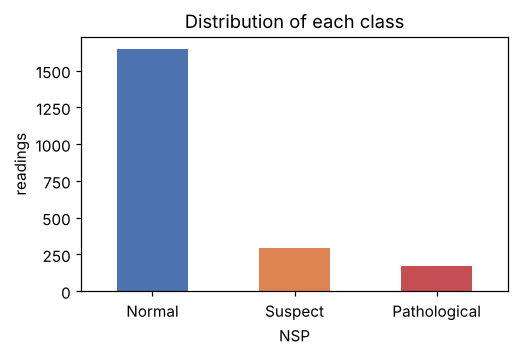

In [5]:
# Duplicates: same measurements and same diagnosis (all inside the same exam)
dup = df.duplicated(subset=SIS_ALL + ["NSP"])
print("Exact duplicates removed:", int(dup.sum()))
df = df[~dup].reset_index(drop=True)
print("Rows with the same measurements as another row but a different diagnosis (kept):",
      int(df.duplicated(subset=SIS_ALL).sum()))
print("Rows after cleaning:", len(df))

counts = df["NSP"].astype(int).map({1: "Normal", 2: "Suspect", 3: "Pathological"}).value_counts().reindex(CLASS_NAMES)
print(pd.DataFrame({"readings": counts, "%": (counts / counts.sum() * 100).round(1)}))
counts.plot.bar(color=["#4C72B0", "#DD8452", "#C44E52"], figsize=(5, 3), rot=0, title="Distribution of each class")
plt.ylabel("readings"); plt.show()

Recording length: 2 to 60 minutes
Share of zeros (%): {'FM': 61.6, 'DS': 99.7, 'DP': 91.6}


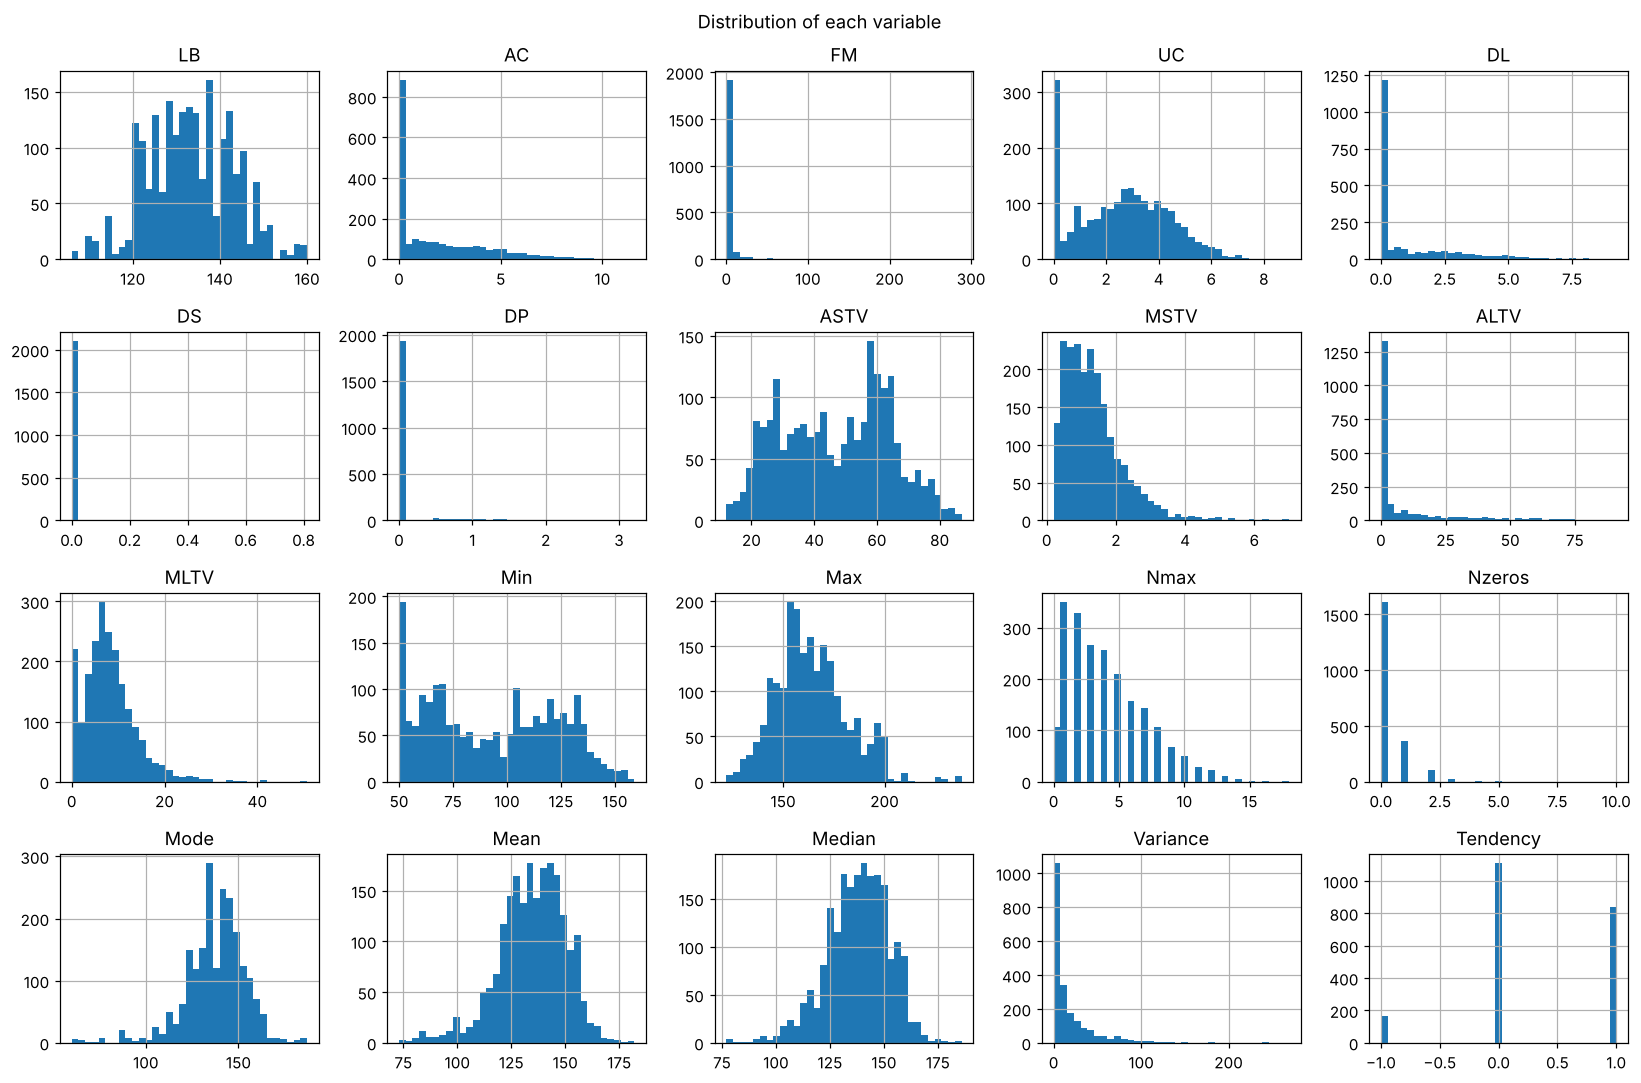

352 exams, 1 to 34 pieces per exam, 6 on average


In [6]:
df["duration"] = df["e"] - df["b"]
print(f"Recording length: {df.duration.min() / 60:.0f} to {df.duration.max() / 60:.0f} minutes")
for c in COUNTS:
    df[c] = df[c] / df["duration"] * 600          # events per 10 minutes
FEATURES = ["LB", "AC", "FM", "UC", "DL", "DS", "DP", "ASTV", "MSTV", "ALTV", "MLTV",
            "Min", "Max", "Nmax", "Nzeros", "Mode", "Mean", "Median", "Variance", "Tendency"]
df["y"] = df["NSP"].astype(int) - 1                # 0 Normal, 1 Suspect, 2 Pathological

print("Share of zeros (%):", (df[["FM", "DS", "DP"]] == 0).mean().mul(100).round(1).to_dict())
df[FEATURES].hist(bins=35, figsize=(15, 10), layout=(4, 5)); plt.suptitle("Distribution of each variable"); plt.tight_layout(); plt.show()

per_exam = df.groupby("FileName").size()
print(f"{df.FileName.nunique()} exams, {per_exam.min()} to {per_exam.max()} pieces per exam, {per_exam.mean():.0f} on average")

### 2.2. Pre-processing
`LBE`, `DR`, `Width`, `SegFile`, `b`, `e` and the expert labels are not in `FEATURES`. `FileName` is kept only as the group key for splitting.

The test set is set aside **before** any choice that uses the data (Section 3), so the choices below are made on the development set only.

In [7]:
X_all, y_all, groups_all = df[FEATURES], df["y"].values, df["FileName"].to_numpy(dtype=object)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
dev_idx, test_idx = next(outer.split(X_all, y_all, groups_all))
dev, test = df.iloc[dev_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
X_dev, y_dev, g_dev = dev[FEATURES], dev["y"].values, dev["FileName"].to_numpy(dtype=object)
X_test, y_test, g_test = test[FEATURES], test["y"].values, test["FileName"].to_numpy(dtype=object)

# The 10 most skewed variables (skewness > 1), measured on the development set
SKEWED = X_dev.skew()[X_dev.skew() > 1].index.tolist()
SKEWED_IDX = [FEATURES.index(c) for c in SKEWED]
print("log1p applied to:", SKEWED)

# Highly correlated variables
corr = X_dev.corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("Pairs with |r| > 0.8:\n", pairs[pairs.abs() > 0.8].round(3).to_string())

# PCA: components needed for 95% of the information
prep_view = SkPipeline([("log", ColumnTransformer([("log", FunctionTransformer(np.log1p), SKEWED)], remainder="passthrough")),
                        ("scale", StandardScaler())])
cum = np.cumsum(PCA().fit(prep_view.fit_transform(X_dev)).explained_variance_ratio_)
print(f"PCA: {np.argmax(cum >= .95) + 1} of {len(FEATURES)} components for 95% of the variance")

def log_scale_prep():
    # fill missing values, log1p on skewed variables, rescale (used for logistic regression, SVM, kNN)
    return [("impute", SimpleImputer(strategy="median")),
            ("log", ColumnTransformer([("log", FunctionTransformer(np.log1p), SKEWED_IDX)], remainder="passthrough")),
            ("scale", StandardScaler())]

log1p applied to: ['AC', 'FM', 'DL', 'DS', 'DP', 'MSTV', 'ALTV', 'MLTV', 'Nzeros', 'Variance']
Pairs with |r| > 0.8:
 LB    Median    0.825
Mode  Mean      0.900
      Median    0.957
Mean  Median    0.951
PCA: 13 of 20 components for 95% of the variance


## 3. Train/Test
`StratifiedGroupKFold` keeps every exam in a single set while keeping the same share of each class in every set.

In [8]:
print("Exams in both sets:", len(set(g_dev) & set(g_test)))
display(pd.DataFrame({
    "exams": [dev.FileName.nunique(), test.FileName.nunique()], "segments": [len(dev), len(test)],
    **{f"% {n}": [np.mean(y_dev == k) * 100, np.mean(y_test == k) * 100] for k, n in enumerate(CLASS_NAMES)},
    "exams with Pathological": [dev[dev.y == 2].FileName.nunique(), test[test.y == 2].FileName.nunique()],
}, index=["development", "test (frozen)"]).round(1))

Exams in both sets: 0


,exams,segments,% Normal,% Suspect,% Pathological,exams with Pathological
development,280,1690,77.9,13.8,8.3,42
test (frozen),72,422,78.0,14.0,8.1,8


### 3.1. Measuring performance

In [9]:
def macro_pr_auc(y_true, proba):
    return average_precision_score(label_binarize(y_true, classes=[0, 1, 2]), proba, average="macro")

SCORING = {"macro_f1": "f1_macro",
           "recall_path": make_scorer(recall_score, labels=[2], average="macro"),
           "recall_susp": make_scorer(recall_score, labels=[1], average="macro"),
           "accuracy": "accuracy",
           "macro_pr_auc": make_scorer(macro_pr_auc, response_method="predict_proba")}
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(model, cv=CV, name=None):
    r = cross_validate(model, X_dev, y_dev, groups=g_dev, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    row = {k: np.mean(r[f"test_{k}"]) for k in SCORING}
    row["macro_f1 std"] = np.std(r["test_macro_f1"])
    row["train macro_f1"] = np.mean(r["train_macro_f1"])
    row["train-validation gap"] = row["train macro_f1"] - row["macro_f1"]
    return pd.Series(row, name=name)

### 3.2. Checking underfitting and overfitting

Decision tree: best depth 10 (validation macro-F1 0.757); deepest tree: training 0.998 vs validation 0.753


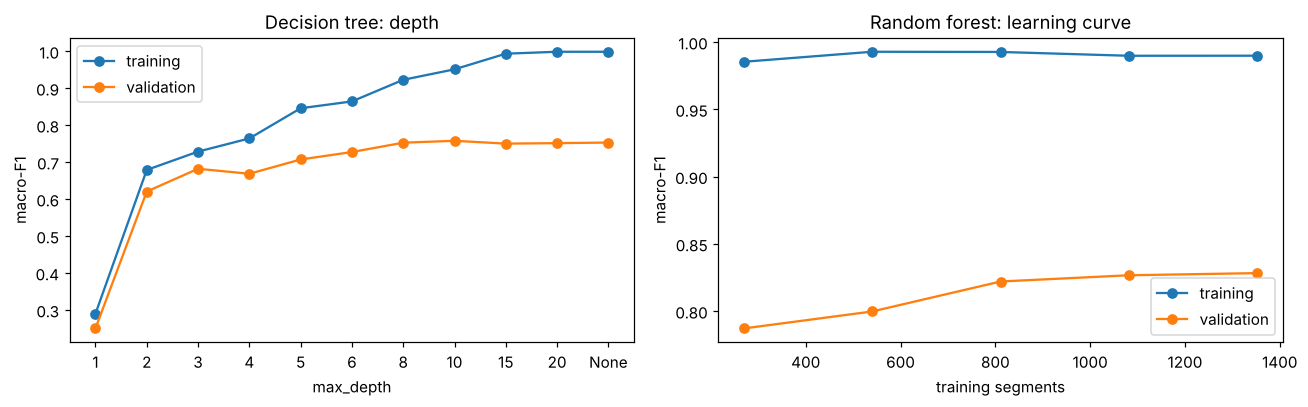

In [10]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]
tree = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
tr, va = validation_curve(tree, X_dev, y_dev, groups=g_dev, param_name="max_depth", param_range=depths,
                          cv=CV, scoring="f1_macro", n_jobs=-1)
best_depth = depths[int(np.argmax(va.mean(1)))]
print(f"Decision tree: best depth {best_depth} (validation macro-F1 {va.mean(1).max():.3f}); "
      f"deepest tree: training {tr.mean(1)[-1]:.3f} vs validation {va.mean(1)[-1]:.3f}")

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
sizes, ltr, lva = learning_curve(rf, X_dev, y_dev, groups=g_dev, cv=CV, scoring="f1_macro",
                                 train_sizes=np.linspace(.2, 1, 5), n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); lab = [str(d) for d in depths]
ax[0].plot(lab, tr.mean(1), "o-", label="training"); ax[0].plot(lab, va.mean(1), "o-", label="validation")
ax[0].set(title="Decision tree: depth", xlabel="max_depth", ylabel="macro-F1"); ax[0].legend()
ax[1].plot(sizes, ltr.mean(1), "o-", label="training"); ax[1].plot(sizes, lva.mean(1), "o-", label="validation")
ax[1].set(title="Random forest: learning curve", xlabel="training segments", ylabel="macro-F1"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Baseline
### 4.1. Majority-class reference

In [11]:
display(pd.DataFrame([evaluate(DummyClassifier(strategy="most_frequent"), name="Always Normal"),
                      evaluate(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE), name="Random by class share")])
        [["macro_f1", "recall_path", "recall_susp", "accuracy"]].round(3))

,macro_f1,recall_path,recall_susp,accuracy
Always Normal,0.292,0.0,0.000,0.779
Random by class share,0.351,0.1,0.154,0.649


### 4.2. Logistic regression
Pipeline: fill missing values with the median → log1p on the 10 skewed variables → rescale → logistic regression. `C` is tuned from 0.001 to 100 for each way of handling imbalance.

In [12]:
C_GRID = np.logspace(-3, 2, 11)
def lr_pipe(strategy):
    steps = log_scale_prep()
    if strategy == "SMOTE": steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", LogisticRegression(max_iter=5000, class_weight="balanced" if strategy == "class_weight" else None)))
    return Pipeline(steps)

rows, grids = [], {}
for strategy in ["none", "class_weight", "SMOTE"]:
    gs = GridSearchCV(lr_pipe(strategy), {"clf__C": C_GRID}, cv=CV, scoring=SCORING, refit="macro_f1",
                      return_train_score=True, n_jobs=-1).fit(X_dev, y_dev, groups=g_dev)
    grids[strategy] = gs; cr = pd.DataFrame(gs.cv_results_); i = gs.best_index_
    rows.append(pd.Series({"best C": gs.best_params_["clf__C"], "macro_f1": cr.loc[i, "mean_test_macro_f1"],
                           "macro_f1 std": cr.loc[i, "std_test_macro_f1"], "train macro_f1": cr.loc[i, "mean_train_macro_f1"],
                           "recall_path": cr.loc[i, "mean_test_recall_path"], "recall_susp": cr.loc[i, "mean_test_recall_susp"]}, name=strategy))
lr_table = pd.DataFrame(rows); display(lr_table.round(3))

# Macro-F1 scores within one std of the best are treated as equal; among them, keep the best Pathological recall
best = lr_table["macro_f1"].max(); sd = lr_table.loc[lr_table["macro_f1"].idxmax(), "macro_f1 std"]
best_strategy = lr_table[lr_table["macro_f1"] >= best - sd]["recall_path"].idxmax()
baseline = grids[best_strategy].best_estimator_
print(f"Selected: {best_strategy}, C = {lr_table.loc[best_strategy, 'best C']:.3g}")

,best C,macro_f1,macro_f1 std,train macro_f1,recall_path,recall_susp
none,0.100,0.765,0.030,0.801,0.643,0.648
class_weight,0.010,0.747,0.032,0.762,0.771,0.846
SMOTE,0.003,0.751,0.033,0.760,0.757,0.850


Selected: class_weight, C = 0.01


              precision    recall  f1-score   support

      Normal      0.982     0.844     0.908      1317
     Suspect      0.517     0.845     0.642       233
Pathological      0.607     0.771     0.679       140

    accuracy                          0.838      1690
   macro avg      0.702     0.820     0.743      1690
weighted avg      0.887     0.838     0.852      1690



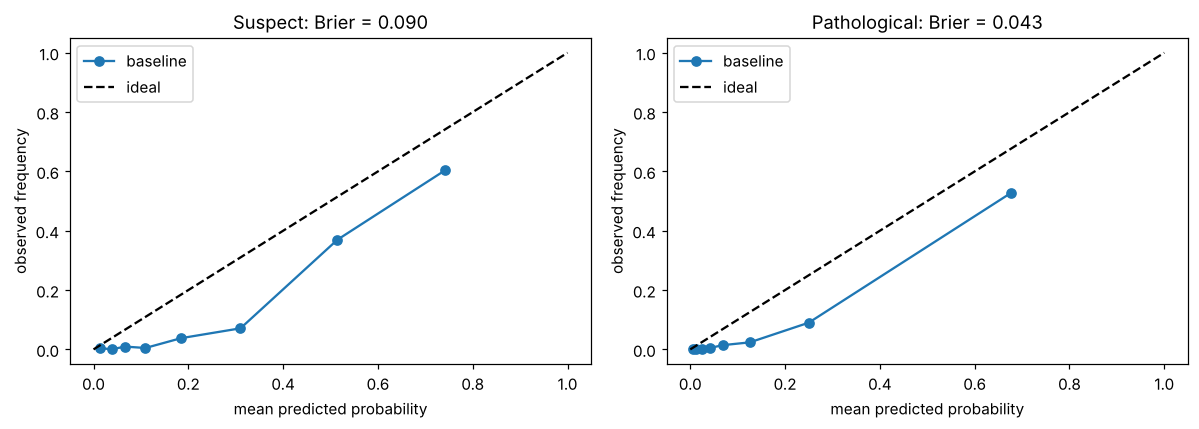

,"odds ratio, Pathological"
ASTV,1.55
DP,1.47
LB,1.27
ALTV,1.20


In [13]:
oof_proba_lr = cross_val_predict(baseline, X_dev, y_dev, groups=g_dev, cv=CV, method="predict_proba", n_jobs=-1)
print(classification_report(y_dev, oof_proba_lr.argmax(1), target_names=CLASS_NAMES, digits=3))

# Are the probabilities trustworthy?
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, a in zip([1, 2], ax):
    frac, mean_p = calibration_curve(y_dev == k, oof_proba_lr[:, k], n_bins=8, strategy="quantile")
    a.plot(mean_p, frac, "o-", label="baseline"); a.plot([0, 1], [0, 1], "k--", label="ideal")
    a.set(title=f"{CLASS_NAMES[k]}: Brier = {brier_score_loss(y_dev == k, oof_proba_lr[:, k]):.3f}",
          xlabel="mean predicted probability", ylabel="observed frequency"); a.legend()
plt.tight_layout(); plt.show()

# What drives its predictions? exp(coefficient) per standard deviation
feat_order = SKEWED + [f for f in FEATURES if f not in SKEWED]
odds = pd.DataFrame(np.exp(baseline.named_steps["clf"].coef_.T), index=feat_order, columns=CLASS_NAMES)
display(odds["Pathological"].sort_values(ascending=False).head(4).round(2).to_frame("odds ratio, Pathological"))

## 5. Benchmark models

In [14]:
BENCH = {
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=.8, colsample_bytree=.8,
                             random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, class_weight="balanced",
                               random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
    "Random forest": rf,
    "Extra trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": Pipeline(log_scale_prep() + [("clf", SVC(C=10, gamma="scale", class_weight="balanced", probability=True, random_state=RANDOM_STATE))]),
    "Decision tree": DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE),
    "kNN (k=7)": Pipeline(log_scale_prep() + [("clf", KNeighborsClassifier(7))]),
    "Logistic regression (baseline)": baseline,
}
bench = pd.DataFrame([evaluate(m, name=n) for n, m in BENCH.items()])
display(bench[["macro_f1", "recall_path", "train-validation gap"]].sort_values("macro_f1", ascending=False).round(3))

,macro_f1,recall_path,train-validation gap
XGBoost,0.866,0.871,0.132
HistGradientBoosting,0.861,0.857,0.137
LightGBM,0.844,0.871,0.154
Random forest,0.839,0.871,0.151
Extra trees,0.787,0.736,0.212
SVM,0.773,0.757,0.154
Decision tree,0.757,0.679,0.193
kNN (k=7),0.751,0.636,0.098
Logistic regression (baseline),0.747,0.771,0.014


## 6. First AutoML pipeline
### 6.1. Setup
FLAML stops after 240 seconds, so a new search can give a different result on a faster or slower machine. The first run therefore saves the result to `automl_result.json`; every later run reloads it, so the numbers below never change. Delete the file to run a new search.

In [15]:
import json, os
AUTOML_FILE = "automl_result.json"
LEARNERS = {"xgboost": XGBClassifier, "lgbm": LGBMClassifier, "rf": RandomForestClassifier,
            "extra_tree": ExtraTreesClassifier, "lrl1": LogisticRegression, "lrl2": LogisticRegression}
if os.path.exists(AUTOML_FILE):
    saved = json.load(open(AUTOML_FILE))
    print(f"Loaded the saved AutoML search from {AUTOML_FILE}")
else:
    automl = AutoML()
    automl.fit(X_train=X_dev, y_train=y_dev, task="classification", metric="macro_f1",
               estimator_list=["lgbm", "xgboost", "rf", "extra_tree", "lrl1", "lrl2"],
               eval_method="cv", split_type=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
               groups=g_dev, time_budget=240, seed=RANDOM_STATE, verbose=0, log_file_name="flaml.log")
    saved = {"winner": automl.best_estimator,
             "winner_params": automl.model.estimator.get_params(),
             "best_macro_f1_per_model": {k: 1 - v for k, v in automl.best_loss_per_estimator.items() if v is not None}}
    json.dump(saved, open(AUTOML_FILE, "w"), indent=2, default=float)
    print(f"Search finished and saved to {AUTOML_FILE}")

display(pd.Series(saved["best_macro_f1_per_model"]).sort_values(ascending=False).round(3).to_frame("best macro-F1"))
WINNER = saved["winner"]
auto_model = LEARNERS[WINNER](**saved["winner_params"])
print("Winner:", WINNER, {k: v for k, v in saved["winner_params"].items()
                          if k in ["n_estimators", "max_leaves", "num_leaves", "max_depth", "learning_rate", "subsample", "colsample_bytree"]})

Loaded the saved AutoML search from automl_result.json


,best macro-F1
lgbm,0.867
xgboost,0.858
rf,0.839
extra_tree,0.820
lrl2,0.738
lrl1,0.703


Winner: lgbm {'colsample_bytree': 1.0, 'learning_rate': 0.4429116340982009, 'max_depth': -1, 'n_estimators': 543, 'num_leaves': 4, 'subsample': 1.0}


### 6.2. Evaluation protocol
Second check of the winner on a new split by exam, then the threshold on P(Pathological), chosen on the development set only.

In [16]:
CV2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)
display(evaluate(auto_model, cv=CV2, name=f"AutoML {WINNER}, new split")[["macro_f1", "recall_path", "train-validation gap"]].round(3).to_frame().T)

oof_auto = cross_val_predict(auto_model, X_dev, y_dev, groups=g_dev, cv=CV, method="predict_proba", n_jobs=-1)
def decide(proba, t_path):
    return np.where(proba[:, 2] >= t_path, 2, np.where(proba[:, 1] > proba[:, 0], 1, 0))
grid_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
recalls = np.array([recall_score(y_dev, decide(oof_auto, t), labels=[2], average="macro") for t in grid_t])
T_PATH = float(grid_t[recalls >= 0.90].max())
print("Threshold on P(Pathological):", T_PATH)

,macro_f1,recall_path,train-validation gap
"AutoML lgbm, new split",0.85,0.843,0.148


Threshold on P(Pathological): 0.17


### 6.3. Results
Both models are frozen, retrained on all development exams and tested once on the test exams. The 95% ranges come from resampling whole exams 1,000 times.

,macro_f1,recall_path,precision_path,recall_susp,accuracy,macro_pr_auc
Baseline logistic regression,"0.763 [0.56, 0.87]","0.676 [0.00, 0.88]","0.535 [0.00, 0.95]","0.932 [0.85, 1.00]","0.872 [0.81, 0.93]","0.817 [0.59, 0.92]"
AutoML lgbm,"0.877 [0.81, 0.93]","0.735 [0.55, 1.00]","0.926 [0.71, 1.00]","0.780 [0.61, 0.91]","0.941 [0.90, 0.97]","0.911 [0.83, 0.97]"
AutoML lgbm + threshold 0.17,"0.898 [0.84, 0.94]","0.853 [0.79, 1.00]","0.906 [0.67, 1.00]","0.780 [0.61, 0.91]","0.948 [0.92, 0.97]","0.911 [0.83, 0.97]"


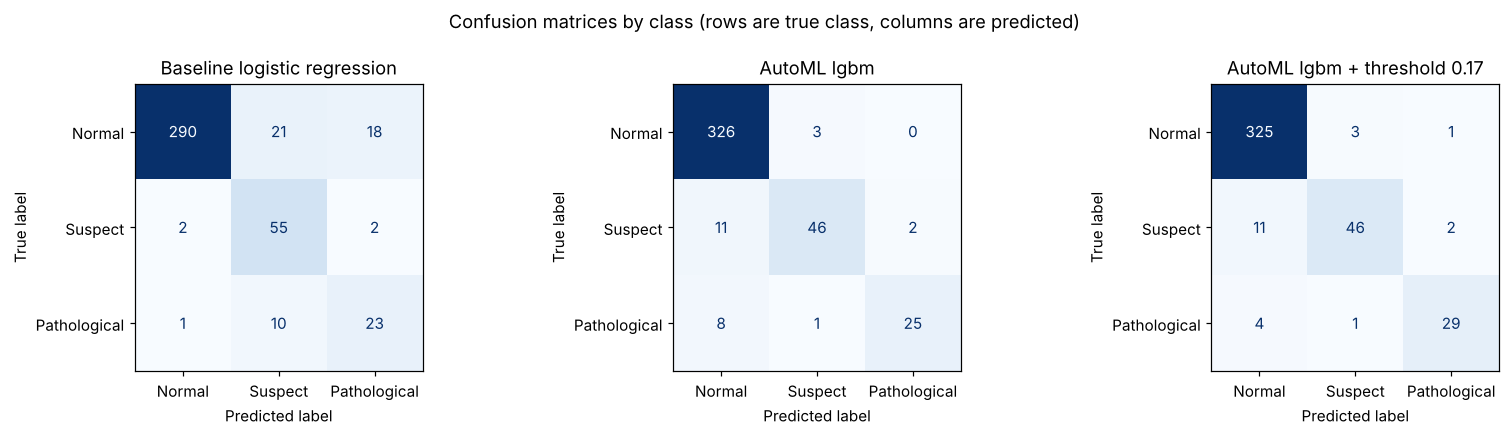

In [17]:
def test_metrics(y, pred, proba):
    return {"macro_f1": f1_score(y, pred, average="macro"),
            "recall_path": recall_score(y, pred, labels=[2], average="macro"),
            "precision_path": precision_score(y, pred, labels=[2], average="macro", zero_division=0),
            "recall_susp": recall_score(y, pred, labels=[1], average="macro"),
            "accuracy": accuracy_score(y, pred), "macro_pr_auc": macro_pr_auc(y, proba)}

def exam_bootstrap(y, pred, proba, groups, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); exams = np.unique(groups)
    idx_by_exam = {g: np.where(groups == g)[0] for g in exams}; out = []
    for _ in range(n):
        idx = np.concatenate([idx_by_exam[g] for g in rng.choice(exams, len(exams), replace=True)])
        if len(np.unique(y[idx])) == 3: out.append(test_metrics(y[idx], pred[idx], proba[idx]))
    return pd.DataFrame(out).quantile([.025, .975])

final_lr = clone(baseline).fit(X_dev, y_dev); final_auto = clone(auto_model).fit(X_dev, y_dev)
results, preds = {}, {}
for name, model, t in [("Baseline logistic regression", final_lr, None), (f"AutoML {WINNER}", final_auto, None),
                       (f"AutoML {WINNER} + threshold {T_PATH}", final_auto, T_PATH)]:
    proba = model.predict_proba(X_test)
    pred = proba.argmax(1) if t is None else decide(proba, t)
    m = test_metrics(y_test, pred, proba); ci = exam_bootstrap(y_test, pred, proba, g_test)
    results[name] = {k: f"{v:.3f} [{ci.loc[.025, k]:.2f}, {ci.loc[.975, k]:.2f}]" for k, v in m.items()}; preds[name] = pred
display(pd.DataFrame(results).T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion matrices by class (rows are true class, columns are predicted)"); plt.tight_layout(); plt.show()

**Time test.** Trained on 1995–96, tested on 1997–98 (exams dated 1980 left out).

In [18]:
dated = df[df.Date.dt.year >= 1995]
past, future = dated[dated.Date.dt.year <= 1996], dated[dated.Date.dt.year >= 1997]
print(f"Train: {len(past)} segments, {past.FileName.nunique()} exams | Test: {len(future)} segments, {future.FileName.nunique()} exams")
p_t = clone(auto_model).fit(past[FEATURES], past["y"]).predict_proba(future[FEATURES])
display(pd.Series(test_metrics(future["y"].values, p_t.argmax(1), p_t)).round(3).to_frame("time test").T)

d = dated.assign(year=dated.Date.dt.year, file_format=dated.FileName.str.extract(r"\.(\w+)$")[0])
display(pd.crosstab(d.year, d.file_format))
display(pd.crosstab(d.year, d.y.map(dict(enumerate(CLASS_NAMES))), normalize="index").mul(100).round(1))
print("Exams with Suspect readings in 1997-98:", future[future.y == 1].FileName.nunique())

Train: 1473 segments, 290 exams | Test: 583 segments, 45 exams


,macro_f1,recall_path,precision_path,recall_susp,accuracy,macro_pr_auc
time test,0.478,0.437,0.844,0.667,0.647,0.561


file_format,dat,dsp,txt
year,,,
1995,0,0,311
1996,795,0,367
1997,54,276,0
1998,0,244,9


y,Normal,Pathological,Suspect
year,,,
1995,50.8,13.8,35.4
1996,82.5,3.4,14.0
1997,86.1,12.7,1.2
1998,80.2,17.8,2.0


Exams with Suspect readings in 1997-98: 3
